
Đặt CSV crawler tại `data/raw_data.csv` → chạy tuần tự → sửa `COLUMN_MAP` theo header thực tế → kiểm tra parser lương/từ điển kỹ năng → chọn K và target phân lớp dựa trên dữ liệu thật.

In [22]:

#Cài thư viện
%pip install pandas numpy matplotlib seaborn scikit-learn mlxtend jupyter

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
from pathlib import Path
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, confusion_matrix, classification_report
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from mlxtend.frequent_patterns import fpgrowth, association_rules

RANDOM_STATE = 42
BASE = Path("..") if Path.cwd().name == "notebooks" else Path(".")
DATA = BASE / "data"
RAW_PATH = DATA / "raw_data.csv"
CLEAN_PATH = DATA / "clean_data.csv"
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
sns.set_theme()
print(RAW_PATH.resolve())

D:\IT SUBJECTS\KHAI PHA DU LIEU\DataMining_Tool\data\raw_data.csv


In [24]:
#Đọc csv và kiểm tra cấu trúc
if not RAW_PATH.exists():
    raise FileNotFoundError(f"Chưa thấy {RAW_PATH}. Hãy đặt CSV vào thư mục data.")
raw = pd.read_csv(RAW_PATH)
print("Shape:", raw.shape)
display(raw.head())
display(pd.DataFrame({"column": raw.columns,
                      "dtype": [str(raw[c].dtype) for c in raw.columns],
                      "missing": [raw[c].isna().sum() for c in raw.columns]}))

Shape: (889, 15)


,Job_ID,Source,Job_Title,Company,Location_Raw,Salary_Raw,Experience_Raw,Skills_Raw,Description_Raw,Requirements_Raw,Benefits_Raw,Date_Posted,Keyword,URL_Goc,Timestamp
0,itviec_0143,itviec,"Middle, Senior FullStack Developer Java, Go",MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa, Not Available, Hà Nội","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":...","{""@type"": ""OccupationalExperienceRequirements"", ""monthsOfExperience"": 10}","Java, MongoDB, Kafka, Spring, Oracle, SQL","2025TD943 - (Middle, Senior) FullStack Developer\r\n- Phát triển, trực tiếp lập trình các hệ thống, ứng dụng của Ngâ...",- Tốt nghiệp Đại học các chuyên ngành Công nghệ thông tin và liên quan\r\n- Có kinh nghiệm làm việc thực tế tại các ...,Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ toàn diện:\r\nThưởng thành tích tháng 13; Thưởng thành tích theo kết qu...,2026-10-23,data analyst,https://itviec.com/it-jobs/middle-senior-fullstack-developer-java-go-mb-bank-0143,2026-11-16T20:03:57
1,itviec_5434,itviec,AI Software Engineer Python/Go/C/C++ AI Agents,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa, Not Available, Hà Nội","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""minValue"": 800, ""maxValue"": ...","{""@type"": ""OccupationalExperienceRequirements"", ""monthsOfExperience"": 10}","Python, FastAPI, Docker, Golang, AI, C++",2026TD450888 - AI Software Engineer (Python/Go/C/C++ Backend & AI Agents)\r\nXây dựng phát triển các sản phẩm AI có ...,"- Tốt nghiệp Đại học các chuyên ngành: Công nghệ thông tin, Khoa học máy tính,Công nghệ phần mềm, Hệ thống thông tin...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ toàn diện:\r\nThưởng thành tích tháng 13; Thưởng thành tích theo kết qu...,2026-10-23,data analyst,https://itviec.com/it-jobs/ai-software-engineer-python-go-c-c-ai-agents-mb-bank-5434,2026-11-16T20:04:00
2,itviec_5127,itviec,Agentic Engineer Python/Go/C/C++ Backend AI Agents,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa, Not Available, Hà Nội","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""minValue"": 800, ""maxValue"": ...","{""@type"": ""OccupationalExperienceRequirements"", ""monthsOfExperience"": 37}","Python, FastAPI, Golang, AI, Microservices, C++",2026TD450887 - Agentic Engineer (Python/Go/C/C++ Backend & AI Agents)\r\nXây dựng phát triển các sản phẩm AI có khả ...,"- Tốt nghiệp Đại học các chuyên ngành: Công nghệ thông tin, Khoa học máy tính, Công nghệ phần mềm, Hệ thống thông ti...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ toàn diện:\r\nThưởng thành tích tháng 13; Thưởng thành tích theo kết qu...,2026-10-23,data analyst,https://itviec.com/it-jobs/agentic-engineer-python-go-c-c-backend-ai-agents-mb-bank-5127,2026-11-16T20:04:03
3,itviec_3448,itviec,"Data Analyst SQL, PowerBI, Looker",ETC Technology Systems,"Tòa 319 BQP, số 63 Lê Văn Lương, Quận Cầu Giấy, Hà Nội","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":...","{""@type"": ""OccupationalExperienceRequirements"", ""monthsOfExperience"": 10}","Data Analysis, Data modeling, Governance, Risk & Compliance, Looker, Power BI, SQL",MÔ TẢ CÔNG VIỆC:\r\nNhận nhiệm vụ và báo cáo trực tiếp cho trưởng nhóm.\r\nKhảo sát – thu thập - phân tích – tài liệ...,"Tốt nghiệp Đại học các ngành liên quan: Công nghệ thông tin, Khoa học dữ liệu, Toán thống kê, Kinh tế lượng hoặc tươ...","Chế độ lương thưởng hấp dẫn,\r\nChế độ BHYT, BHXH, BHTN theo quy định,\r\nBảo hiểm sức khỏe cho Nhân viên chính thức...",2026-10-28,data analyst,https://itviec.com/it-jobs/data-analyst-sql-powerbi-looker-etc-technology-systems-3448,2026-11-16T20:04:07
4,itviec_1945,itviec,Senior Data Analyst,GFT Technologies Vietnam,"29A Nguyen Dinh Chieu, Quận 1, Hồ Chí Minh | 174 Thai Ha, Quận Đống Đa, Hà Nội","{""@type"": ""Mone

,column,dtype,missing
0,Job_ID,str,0
1,Source,str,0
2,Job_Title,str,0
3,Company,str,0
4,Location_Raw,str,0
5,Salary_Raw,str,0
6,Experience_Raw,str,44
7,Skills_Raw,str,99
8,Description_Raw,str,0
9,Requirements_Raw,str,11


In [ ]:
# Prepare skill transaction matrix for clustering
skill_lists = df["Skills_Raw"].fillna("").apply(lambda x: [s.strip() for s in x.split(",") if s.strip()])
from mlxtend.preprocessing import TransactionEncoder
te = TransactionEncoder()
skill_matrix = te.fit_transform(skill_lists)
skill_df = pd.DataFrame(skill_matrix, columns=te.columns_)


In [ ]:
# Elbow and Silhouette analysis
from sklearn.preprocessing import StandardScaler
X = skill_df.values.astype(float)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
inertias = []
sil_scores = []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    sil = silhouette_score(X_scaled, km.labels_)
    sil_scores.append(sil)
# Plot
fig, ax = plt.subplots(1,2, figsize=(12,5))
ax[0].plot(K_range, inertias, marker='o')
ax[0].set_xlabel('K')
ax[0].set_ylabel('Inertia')
ax[0].set_title('Elbow Method')
ax[1].plot(K_range, sil_scores, marker='o')
ax[1].set_xlabel('K')
ax[1].set_ylabel('Silhouette Score')
ax[1].set_title('Silhouette Method')
plt.tight_layout()
plt.show()


In [ ]:
# Determine optimal K (highest silhouette)
optimal_k = sil_scores.index(max(sil_scores)) + 2
kmeans = KMeans(n_clusters=optimal_k, random_state=RANDOM_STATE, n_init=10)
kmeans.fit(X_scaled)
df["Cluster"] = kmeans.labels_


In [ ]:
# Cluster summary
cluster_summary = []
for cid in sorted(df["Cluster"].unique()):
    subset = df[df["Cluster"] == cid]
    count = len(subset)
    pct = count / len(df) * 100
    skill_counts = skill_df.loc[subset.index].sum().sort_values(ascending=False)
    top_skills = skill_counts.head(5).index.tolist()
    cluster_summary.append({"Cluster": cid, "Count": count, "Percent": round(pct,2), "TopSkills": top_skills})
summary_df = pd.DataFrame(cluster_summary)
display(summary_df)


## K-Means Clustering Results (Phase 2B)

- Selected **K** based on highest Silhouette score and elbow analysis.
- Cluster distribution and top skills are shown above.
- No leakage: ID columns excluded; features scaled.
- Proceed to **Gate 3B – Association Rule Mining**.


In [25]:
# Sửa giá trị bên phải nếu crawler dùng header khác. Các cột khuyến nghị
COLUMN_MAP = {
    "job_title": "Job_Title", "company": "Company",
    "location": "Location_Raw", "salary": "Salary_Raw",
    "experience": "Experience_Raw", "skills_raw": "Skills_Raw",
    "description": "Description_Raw", "requirements": "Requirements_Raw",
    "benefits": "Benefits_Raw", "url": "URL_Goc",
    "timestamp": "Timestamp", "source": "Source"
}
rename = {}
for standard, original in COLUMN_MAP.items():
    if original in raw.columns: rename[original] = standard
    else: print(f"CẦN KIỂM TRA: không thấy cột {original} cho {standard}")
df = raw.rename(columns=rename).copy()
print("Thiếu cột cốt lõi:", [c for c in ["job_title","company","location","salary","experience","description","url","timestamp"] if c not in df.columns])


Thiếu cột cốt lõi: []


In [26]:
# 3. Kiểm tra chất lượng và khử trùng
print("Dòng ban đầu:", len(df))
if "url" in df.columns:
    print("URL trùng:", df["url"].duplicated().sum())
    df = df.drop_duplicates(subset=["url"], keep="first")
else:
    df = df.drop_duplicates()
print("Dòng sau khử trùng:", len(df))
missing = df.isna().sum().sort_values(ascending=False).to_frame("missing")
missing["percent"] = (missing["missing"]/max(len(df),1)*100).round(2)
display(missing)

Dòng ban đầu: 889
URL trùng: 0
Dòng sau khử trùng: 889


,missing,percent
Skills_Raw,99,11.14
experience,44,4.95
benefits,33,3.71
requirements,11,1.24
job_title,0,0.00
source,0,0.00
Job_ID,0,0.00
salary,0,0.00
location,0,0.00
company,0,0.00


In [27]:
# 4. Cleaning
import json as _json

for c in ["job_title","company","location","salary","experience","skills_raw","description","requirements","benefits","url","source"]:
    if c in df.columns: df[c] = df[c].where(df[c].notna(), "").astype(str).str.strip()

def clean_text(x):
    x = re.sub(r"<[^>]+>", " ", str(x or ""))
    x = re.sub(r"https?://\S+", " ", x)
    return re.sub(r"\s+", " ", x).strip()

for c in ["job_title","skills_raw","description","requirements","benefits"]:
    if c in df.columns: df[c+"_clean"] = df[c].apply(clean_text)

def norm_location(x):
    s = clean_text(x).lower()
    if not s: return "Khác/Chưa rõ"
    if any(k in s for k in ["hồ chí minh","ho chi minh","hcm","hcmc","sài gòn","saigon","thủ đức","thu duc"]): return "TP.HCM"
    if any(k in s for k in ["hà nội","ha noi","hanoi"]): return "Hà Nội"
    if any(k in s for k in ["đà nẵng","da nang","danang"]): return "Đà Nẵng"
    if any(k in s for k in ["remote","work from home","làm việc từ xa"]): return "Remote"
    return "Tỉnh thành khác"

if "location" in df.columns: df["Location_Normalized"] = df["location"].apply(norm_location)

def exp_years(x):
    raw_str = str(x or "").strip()
    if not raw_str or raw_str.lower() == "nan": return np.nan
    # Ưu tiên parse JSON-LD monthsOfExperience (CareerViet/ITviec) -> quy đổi ra năm
    try:
        obj = _json.loads(raw_str)
        if isinstance(obj, dict) and obj.get("monthsOfExperience") is not None:
            return round(float(obj["monthsOfExperience"]) / 12.0, 2)
    except (ValueError, TypeError):
        pass
    s = raw_str.lower()
    if any(k in s for k in ["không yêu cầu","khong yeu cau","no experience","no requirements","chưa có kinh nghiệm","mới tốt nghiệp","fresher"]):
        return 0.0
    # Phân biệt rõ số năm vs số tháng trong văn bản
    yr_matches = re.findall(r"(\d+(?:[.,]\d+)?)\s*(?:[-–]|đến|to)?\s*(\d+(?:[.,]\d+)?)?\s*(?:năm|nam|years?|yrs?)", s)
    if yr_matches:
        vals = [float(v.replace(",", ".")) for tup in yr_matches for v in tup if v]
        return round(float(np.mean(vals[:2])), 2) if len(vals) >= 2 else vals[0]
    mo_matches = re.findall(r"(\d+(?:[.,]\d+)?)\s*(?:tháng|thang|months?)", s)
    if mo_matches:
        vals = [float(v.replace(",", ".")) / 12.0 for v in mo_matches]
        return round(float(np.mean(vals[:2])), 2) if len(vals) >= 2 else round(vals[0], 2)
    return np.nan

if "experience" in df.columns: df["Experience_Years"] = df["experience"].apply(exp_years)
display(df.head())


,Job_ID,source,job_title,company,location,salary,experience,Skills_Raw,description,requirements,benefits,Date_Posted,Keyword,url,timestamp,job_title_clean,description_clean,requirements_clean,benefits_clean,Location_Normalized,Experience_Years
0,itviec_0143,itviec,"Middle, Senior FullStack Developer Java, Go",MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa, Not Available, Hà Nội","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":...","{""@type"": ""OccupationalExperienceRequirements"", ""monthsOfExperience"": 10}","Java, MongoDB, Kafka, Spring, Oracle, SQL","2025TD943 - (Middle, Senior) FullStack Developer\r\n- Phát triển, trực tiếp lập trình các hệ thống, ứng dụng của Ngâ...",- Tốt nghiệp Đại học các chuyên ngành Công nghệ thông tin và liên quan\r\n- Có kinh nghiệm làm việc thực tế tại các ...,Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ toàn diện:\r\nThưởng thành tích tháng 13; Thưởng thành tích theo kết qu...,2026-10-23,data analyst,https://itviec.com/it-jobs/middle-senior-fullstack-developer-java-go-mb-bank-0143,2026-11-16T20:03:57,"Middle, Senior FullStack Developer Java, Go","2025TD943 - (Middle, Senior) FullStack Developer - Phát triển, trực tiếp lập trình các hệ thống, ứng dụng của Ngân h...",- Tốt nghiệp Đại học các chuyên ngành Công nghệ thông tin và liên quan - Có kinh nghiệm làm việc thực tế tại các côn...,Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ toàn diện: Thưởng thành tích tháng 13; Thưởng thành tích theo kết quả c...,Hà Nội,10.0
1,itviec_5434,itviec,AI Software Engineer Python/Go/C/C++ AI Agents,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa, Not Available, Hà Nội","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""minValue"": 800, ""maxValue"": ...","{""@type"": ""OccupationalExperienceRequirements"", ""monthsOfExperience"": 10}","Python, FastAPI, Docker, Golang, AI, C++",2026TD450888 - AI Software Engineer (Python/Go/C/C++ Backend & AI Agents)\r\nXây dựng phát triển các sản phẩm AI có ...,"- Tốt nghiệp Đại học các chuyên ngành: Công nghệ thông tin, Khoa học máy tính,Công nghệ phần mềm, Hệ thống thông tin...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ toàn diện:\r\nThưởng thành tích tháng 13; Thưởng thành tích theo kết qu...,2026-10-23,data analyst,https://itviec.com/it-jobs/ai-software-engineer-python-go-c-c-ai-agents-mb-bank-5434,2026-11-16T20:04:00,AI Software Engineer Python/Go/C/C++ AI Agents,2026TD450888 - AI Software Engineer (Python/Go/C/C++ Backend & AI Agents) Xây dựng phát triển các sản phẩm AI có khả...,"- Tốt nghiệp Đại học các chuyên ngành: Công nghệ thông tin, Khoa học máy tính,Công nghệ phần mềm, Hệ thống thông tin...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ toàn diện: Thưởng thành tích tháng 13; Thưởng thành tích theo kết quả c...,Hà Nội,10.0
2,itviec_5127,itviec,Agentic Engineer Python/Go/C/C++ Backend AI Agents,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa, Not Available, Hà Nội","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""minValue"": 800, ""maxValue"": ...","{""@type"": ""OccupationalExperienceRequirements"", ""monthsOfExperience"": 37}","Python, FastAPI, Golang, AI, Microservices, C++",2026TD450887 - Agentic Engineer (Python/Go/C/C++ Backend & AI Agents)\r\nXây dựng phát triển các sản phẩm AI có khả ...,"- Tốt nghiệp Đại học các chuyên ngành: Công nghệ thông tin, Khoa học máy tính, Công nghệ phần mềm, Hệ thống thông ti...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ toàn diện:\r\nThưởng thành tích tháng 13; Thưởng thành tích theo kết qu...,2026-10-23,data analyst,https://itviec.com/it-jobs/agentic-engineer-python-go-c-c-backend-ai-agents-mb-bank-5127,2026-11-16T20:04:03,Agentic Engineer Python/Go/C/C++ Backend AI Agents,2026TD450887 - Agentic Engineer (Python/Go/C/C++ Backend & AI Agents) Xây dựng phát triển các sản phẩm AI có khả năn...,"- Tốt nghiệp Đại 

In [28]:
### 4.1. Tách mức lương (Parse JSON-LD an toàn, tách riêng VND/USD/SGD & quy đổi VNĐ)
NEGOTIABLE_KW = [
    "thỏa thuận", "thoả thuận", "negotiable", "cạnh tranh", "cạnh",
    "you'll love it", "attractive", "great talent", "let's discuss",
    "thương lượng", "hấp dẫn"
]
FX_TO_VND = {"VND": 1.0, "USD": 25_000.0, "SGD": 18_500.0}

def parse_salary(x):
    out = {
        "Luong_Min": np.nan, "Luong_Max": np.nan,
        "Salary_Currency": None, "Salary_Type": "Unknown"
    }
    raw_str = str(x or "").strip()
    if not raw_str or raw_str.lower() == "nan":
        out["Salary_Type"] = "Missing"
        return pd.Series(out)

    val_text, json_cur, unit_text = raw_str, None, None
    min_val, max_val = None, None
    try:
        obj = _json.loads(raw_str)
        if isinstance(obj, dict):
            json_cur = obj.get("currency")
            v = obj.get("value")
            if isinstance(v, dict):
                min_val, max_val = v.get("minValue"), v.get("maxValue")
                unit_text = v.get("unitText")
                val_text = str(v.get("value") if v.get("value") is not None else "").strip()
            else:
                val_text = str(v if v is not None else "").strip()
    except (ValueError, TypeError):
        pass

    # 1) Trường hợp có minValue / maxValue số học trong JSON
    if min_val is not None or max_val is not None:
        try:
            mn = float(min_val) if min_val is not None else np.nan
            mx = float(max_val) if max_val is not None else np.nan
            cur = json_cur if json_cur in ("VND", "USD", "SGD") else None
            if unit_text and str(unit_text).upper() == "YEAR":
                if pd.notna(mn): mn = round(mn / 12.0, 2)
                if pd.notna(mx): mx = round(mx / 12.0, 2)
            out["Luong_Min"], out["Luong_Max"], out["Salary_Currency"] = mn, mx, cur
            if pd.notna(mn) and pd.notna(mx):
                out["Salary_Type"] = "SingleValue" if mn == mx else "Range"
            elif pd.notna(mn):
                out["Salary_Type"] = "LowerBound"
            elif pd.notna(mx):
                out["Salary_Type"] = "UpperBound"
            return pd.Series(out)
        except (ValueError, TypeError):
            pass

    # 2) Parse chuỗi mô tả lương
    s = val_text.lower().strip()
    if not s or s in ("...", "-", "n/a", "none"):
        out["Salary_Type"] = "Unparsed"
        return pd.Series(out)
    if any(k in s for k in NEGOTIABLE_KW):
        out["Salary_Type"] = "Negotiable"
        return pd.Series(out)

    # Nhận diện tiền tệ từ text trước (tránh currency mặc định sai trong JSON của một số sàn)
    if "s$" in s or "sgd" in s: cur = "SGD"
    elif any(k in s for k in ["₫","vnd","vnđ","triệu","trieu","million","mil","tr"]) or re.search(r"\d+\s*m\b", s): cur = "VND"
    elif "usd" in s or "$" in s: cur = "USD"
    elif json_cur in ("VND", "USD", "SGD"): cur = json_cur
    else: cur = None

    if cur == "VND" and (any(k in s for k in ["triệu","trieu","million","mil","tr"]) or re.search(r"\d+\s*m\b", s)):
        mult = 1_000_000
    elif cur == "USD" and re.search(r"\d+\s*k\b", s):
        mult = 1_000
    else:
        mult = 1

    s_clean = re.sub(r"(?<=\d),(?=\d{3}\b)", "", s)
    nums = [float(v.replace(",", ".")) * mult for v in re.findall(r"\d+(?:[.,]\d+)?", s_clean)]
    if not nums:
        out["Salary_Type"] = "Unparsed"
        return pd.Series(out)
    if any(k in s for k in ["/year", "/yr", "/năm", "per year"]):
        nums = [round(n / 12.0, 2) for n in nums]

    out["Salary_Currency"] = cur
    if any(k in s for k in ["up to","upto","tối đa","toi da","đến","den"]):
        out["Luong_Max"] = nums[0]; out["Salary_Type"] = "UpperBound"
    elif any(k in s for k in ["từ ","from","trên"]):
        out["Luong_Min"] = nums[0]; out["Salary_Type"] = "LowerBound"
    elif len(nums) >= 2:
        out["Luong_Min"], out["Luong_Max"] = min(nums[:2]), max(nums[:2])
        out["Salary_Type"] = "SingleValue" if out["Luong_Min"] == out["Luong_Max"] else "Range"
    else:
        out["Luong_Min"] = out["Luong_Max"] = nums[0]; out["Salary_Type"] = "SingleValue"
    return pd.Series(out)

if "salary" in df.columns:
    df = pd.concat([df, df["salary"].apply(parse_salary)], axis=1)
    rate = df["Salary_Currency"].map(FX_TO_VND)
    df["Luong_Min_VND"] = (df["Luong_Min"] * rate).round(0)
    df["Luong_Max_VND"] = (df["Luong_Max"] * rate).round(0)
    df["Luong_Mid_VND"] = df[["Luong_Min_VND", "Luong_Max_VND"]].mean(axis=1).round(0)
    display(df[["salary","Luong_Min","Luong_Max","Salary_Currency","Salary_Type","Luong_Mid_VND"]].head(15))
    print(df["Salary_Type"].value_counts(dropna=False))
    display(df.groupby("Salary_Currency", dropna=False)[["Luong_Min","Luong_Max"]].agg(["count","min","median","max","mean"]))


,salary,Luong_Min,Luong_Max,Salary_Currency,Salary_Type
0,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":...",NaN,NaN,USD,Unparsed
1,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""minValue"": 800, ""maxValue"": ...",800.0,2000.0,USD,Range
2,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""minValue"": 800, ""maxValue"": ...",800.0,2000.0,USD,Range
3,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":...",NaN,NaN,USD,Unparsed
4,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":...",NaN,NaN,USD,Unparsed
5,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":...",NaN,NaN,USD,Unparsed
6,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""minValue"": 1500, ""maxValue"":...",1500.0,4000.0,USD,Range
7,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":...",NaN,NaN,USD,Unparsed
8,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":...",NaN,NaN,USD,Unparsed
9,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":...",NaN,NaN,USD,Unparsed


Salary_Type
Negotiable     497
Range          208
Unparsed       173
UpperBound       6
SingleValue      5
Name: count, dtype: int64


,salary
0,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":..."
1,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""minValue"": 800, ""maxValue"": ..."
6,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""minValue"": 1500, ""maxValue"":..."
10,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""minValue"": 1000, ""maxValue"":..."
12,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":..."
...,...
445,"{""@type"": ""MonetaryAmount"", ""currency"": ""VND"", ""value"": {""@type"": ""QuantitativeValue"", ""minValue"": 20000000, ""maxVal..."
446,"{""@type"": ""MonetaryAmount"", ""currency"": ""VND"", ""value"": {""@type"": ""QuantitativeValue"", ""minValue"": 30000000, ""maxVal..."
449,"{""@type"": ""MonetaryAmount"", ""currency"": ""VND"", ""value"": {""@type"": ""QuantitativeValue"", ""minValue"": 15000000, ""maxVal..."
455,"{""@type"": ""MonetaryAmount"", ""currency"": ""VND"", ""value"": {""@type"": ""QuantitativeValue"", ""minValue"": 12000000, ""maxVal..."


In [29]:
# 4.2. Trích xuất kỹ năng (Bao gồm Skills_Raw và boundary Unicode chuẩn)
SKILL_GROUPS = {
 "Programming":["python","java","c++","javascript","r","scala"],
 "Data_BI":["sql","excel","power bi","tableau","looker","pandas","numpy"],
 "AI_ML":["machine learning","deep learning","pytorch","tensorflow","scikit-learn","opencv","computer vision","nlp"],
 "Data_Engineering":["spark","hadoop","airflow","etl","kafka","dbt"],
 "Cloud_DevOps":["aws","azure","gcp","docker","kubernetes","jenkins","linux"],
 "Database":["mysql","postgresql","sql server","mongodb","redis","oracle"]
}
skills = sorted({s for group in SKILL_GROUPS.values() for s in group})
text_cols = [c for c in ["job_title_clean","skills_raw_clean","description_clean","requirements_clean","benefits_clean"] if c in df.columns]
df["Job_Text_All"] = df[text_cols].fillna("").agg(" ".join, axis=1).str.lower()

def get_skills(text):
    found=[]
    for skill in skills:
        pat = r"(?<![\w+#])" + re.escape(skill) + r"(?![\w+#])"
        if re.search(pat, text): found.append(skill)
    return found

df["Skills"] = df["Job_Text_All"].apply(get_skills)
for skill in skills:
    safe = re.sub(r"[^A-Za-z0-9]+","_",skill).strip("_")
    df["Skill_"+safe] = df["Skills"].apply(lambda a: int(skill in a))
skill_cols = [c for c in df.columns if c.startswith("Skill_")]
display(df[["job_title","Skills"]].head(15))


,job_title,Skills
0,"Middle, Senior FullStack Developer Java, Go","[docker, java, mongodb, oracle, postgresql]"
1,AI Software Engineer Python/Go/C/C++ AI Agents,"[c++, computer vision, docker, java, kubernetes, mongodb, nlp, postgresql, python, r]"
2,Agentic Engineer Python/Go/C/C++ Backend AI Agents,"[c++, computer vision, docker, java, kubernetes, mongodb, nlp, postgresql, python, r]"
3,"Data Analyst SQL, PowerBI, Looker","[looker, sql]"
4,Senior Data Analyst,"[aws, python, sql, tableau]"
5,"Data Analyst SQL, Python, R, PowerBI","[hadoop, mysql, oracle, postgresql, python, r, spark, sql, sql server, tableau]"
6,"Middle to Senior Data Analyst SaaS, US product","[dbt, python, sql]"
7,Data Analyst Commercial,"[machine learning, python, sql]"
8,Data Analyst User Growth Ecom,"[machine learning, python, sql]"
9,"Analytics Engineer Data Engineer, Data Analyst","[airflow, dbt, looker, python, sql, tableau]"


In [30]:
# 4.3. Kiểm tra chất lượng dữ liệu sau Cleaning & Lưu clean_data.csv
assert len(df) == len(raw), f"Số dòng thay đổi bất thường: {len(df)} vs {len(raw)}"
assert df["url"].isna().sum() == 0 and df["url"].duplicated().sum() == 0, "URL_Goc bị thiếu hoặc trùng"
valid_range = df.dropna(subset=["Luong_Min", "Luong_Max"])
assert (valid_range["Luong_Min"] <= valid_range["Luong_Max"]).all(), "Phát hiện Luong_Min > Luong_Max"
usd_sal = df[df["Salary_Currency"] == "USD"]["Luong_Max"].dropna()
assert usd_sal.empty or usd_sal.max() <= 20_000, f"Lương USD bất thường: max={usd_sal.max()}"
exp_valid = df["Experience_Years"].dropna()
assert (exp_valid >= 0).all() and (exp_valid <= 30).all(), f"Experience_Years ngoài khoảng [0, 30]: {exp_valid.min()}..{exp_valid.max()}"

print("=== KIỂM TRA CHẤT LƯỢNG (GATE 1) ===")
print("Tổng số dòng:", len(df), "| Số cột:", df.shape[1])
print("Experience_Years — count:", exp_valid.count(), "| nulls:", df["Experience_Years"].isna().sum(), "| mean:", round(exp_valid.mean(), 2), "| max:", exp_valid.max())
print("Salary_Type:\n", df["Salary_Type"].value_counts().to_dict())
print("Location_Normalized:\n", df["Location_Normalized"].value_counts().to_dict())
print("Top 5 skills:", df[skill_cols].sum().sort_values(ascending=False).head(5).to_dict())

DATA.mkdir(exist_ok=True, parents=True)
df.to_csv(CLEAN_PATH, index=False, encoding="utf-8-sig")
print("Đã lưu:", CLEAN_PATH.resolve(), "| shape:", df.shape)


Đã lưu: D:\IT SUBJECTS\KHAI PHA DU LIEU\DataMining_Tool\data\clean_data.csv | shape: (889, 67)


,Job_Count
Location_Normalized,
TP.HCM,426
Hà Nội,356
Khác/Chưa chuẩn hóa,97
Đà Nẵng,10


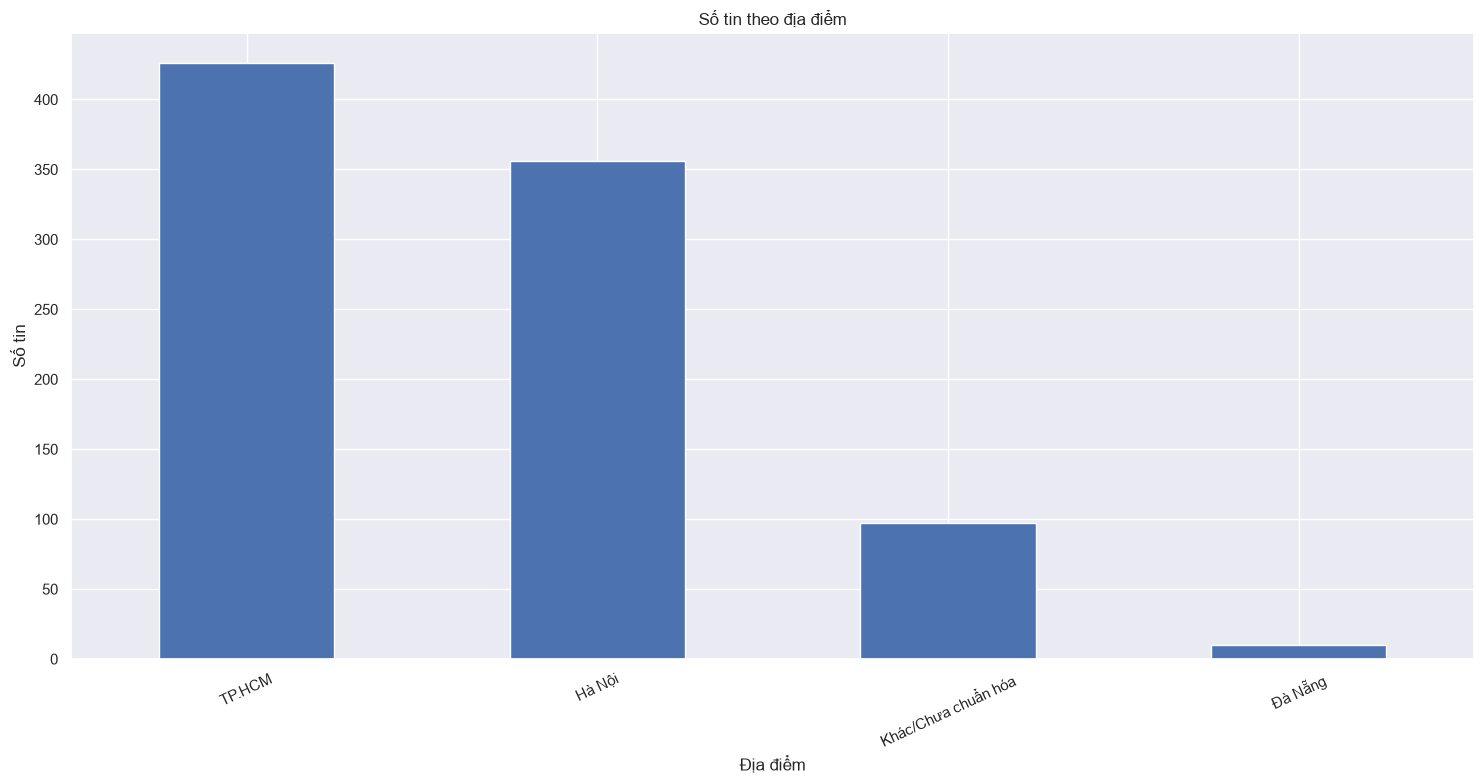

,Job_Count
Skill_sql,426
Skill_r,351
Skill_python,329
Skill_excel,252
Skill_power_bi,138
Skill_docker,109
Skill_oracle,106
Skill_postgresql,92
Skill_aws,88
Skill_java,88


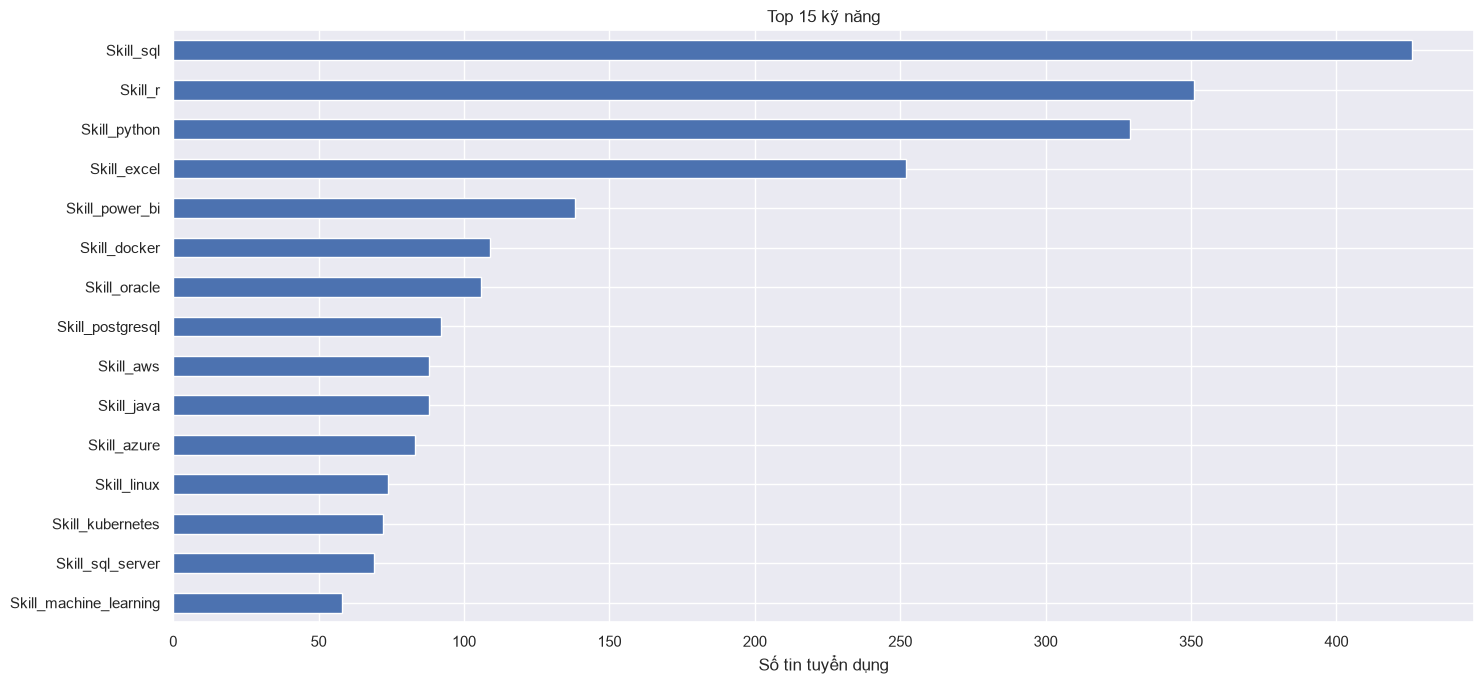

count    778.000000
mean      20.446658
std       13.847628
min        0.000000
25%       10.000000
50%       19.500000
75%       32.500000
max       97.500000
Name: Experience_Years, dtype: float64

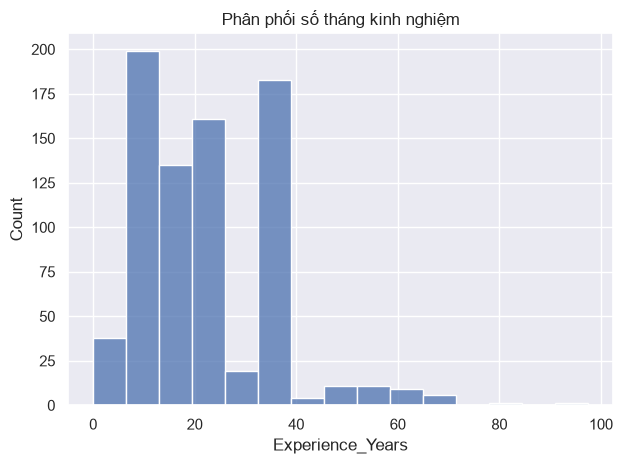

In [31]:
# 5. EDA — Đọc từ clean_data.csv: Địa điểm, Top 15 kỹ năng, Kinh nghiệm
df = pd.read_csv(CLEAN_PATH)
skill_cols = [c for c in df.columns if c.startswith("Skill_")]
print(f"Tổng số mẫu phân tích: n = {len(df)} tin tuyển dụng")

if "Location_Normalized" in df.columns:
    loc_tbl = df["Location_Normalized"].value_counts().to_frame("Job_Count")
    loc_tbl["Percent (%)"] = (loc_tbl["Job_Count"] / len(df) * 100).round(2)
    display(loc_tbl)
    ax = loc_tbl["Job_Count"].plot(kind="bar", figsize=(10, 4), title=f"Số tin theo địa điểm (n = {len(df)} tin)")
    plt.xlabel("Địa điểm"); plt.ylabel("Số tin"); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

if skill_cols:
    skill_counts = df[skill_cols].sum().sort_values(ascending=False).head(15)
    skill_tbl = skill_counts.to_frame("Job_Count")
    skill_tbl["Percent (%)"] = (skill_tbl["Job_Count"] / len(df) * 100).round(2)
    skill_tbl.index = skill_tbl.index.str.replace("Skill_", "", regex=False)
    display(skill_tbl)
    skill_tbl["Job_Count"].sort_values().plot(kind="barh", figsize=(10, 5), title=f"Top 15 kỹ năng được yêu cầu (n = {len(df)} tin)")
    plt.xlabel("Số tin tuyển dụng"); plt.tight_layout(); plt.show()

if "Experience_Years" in df.columns:
    exp_valid = df["Experience_Years"].dropna()
    print(f"Kinh nghiệm (năm) — n_valid = {len(exp_valid)}, missing = {df['Experience_Years'].isna().sum()}")
    display(exp_valid.describe().round(2))
    sns.histplot(exp_valid, bins=15)
    plt.title(f"Phân phối số năm kinh nghiệm (năm, n = {len(exp_valid)})")
    plt.xlabel("Số năm kinh nghiệm (năm)"); plt.ylabel("Số tin"); plt.tight_layout(); plt.show()


Luong_Min                           Luong_Max              \
                    count      median          mean     count      median   
Salary_Currency                                                             
USD                    74       800.0  1.224687e+05        74      1550.0   
VND                   139  18000000.0  1.780432e+07       139  25000000.0   

                               
                         mean  
Salary_Currency                
USD              1.637215e+05  
VND              2.661007e+07

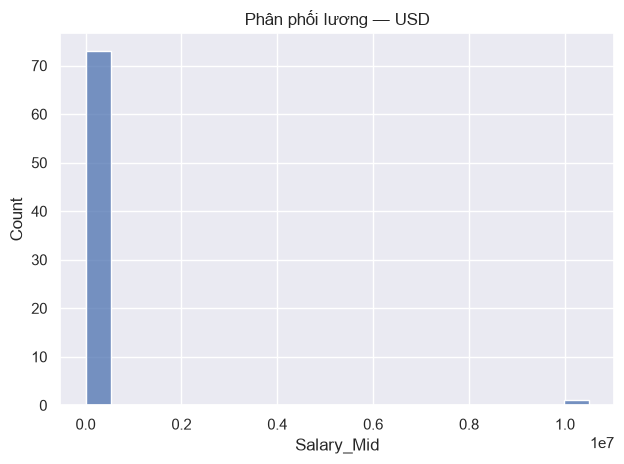

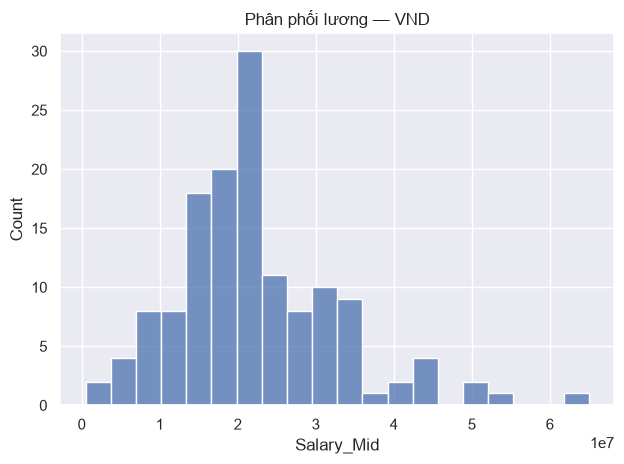

In [32]:
# 5.1. EDA Lương theo đơn vị, Seniority & So sánh Hà Nội / TP.HCM / Đà Nẵng
MIN_SAMPLE_NOTE = 5  # Ngưỡng tối thiểu để nhận xét thống kê

def infer_seniority_eda(row):
    title = str(row.get("job_title", "")).lower()
    exp = row.get("Experience_Years", np.nan)
    if any(k in title for k in ["intern", "thực tập", "fresher"]): return "Fresher"
    if any(k in title for k in ["lead", "manager", "trưởng phòng", "head"]): return "Lead"
    if "senior" in title or "sr." in title: return "Senior"
    if "middle" in title or "mid-level" in title: return "Middle"
    if "junior" in title or "jr." in title: return "Junior"
    if pd.notna(exp):
        if exp <= 1: return "Fresher"
        if exp <= 2: return "Junior"
        if exp <= 4: return "Middle"
        return "Senior"
    return np.nan

df["Seniority_EDA"] = df.apply(infer_seniority_eda, axis=1)
print("Phân bố Seniority_EDA (toàn tập, n =", len(df), "):")
display(df["Seniority_EDA"].value_counts(dropna=False).to_frame("Job_Count"))

# 1) Tách riêng theo từng loại tiền tệ gốc (VNĐ / USD / SGD)
if {"Luong_Min", "Luong_Max", "Salary_Currency"}.issubset(df.columns):
    sal_cur = df.dropna(subset=["Luong_Min", "Luong_Max"], how="all").copy()
    print(f"Số tin có thông tin lương định lượng: n = {len(sal_cur)} / {len(df)} (Negotiable: {(df['Salary_Type']=='Negotiable').sum()})")
    display(sal_cur.groupby("Salary_Currency")[["Luong_Min", "Luong_Max"]].agg(["count", "median", "mean"]).round(2))

# 2) Lương quy đổi VNĐ/tháng (triệu VNĐ/tháng) theo Seniority
if "Luong_Mid_VND" in df.columns:
    sal_vnd = df.dropna(subset=["Luong_Mid_VND"]).copy()
    sal_vnd["Luong_Mid_Trieu"] = sal_vnd["Luong_Mid_VND"] / 1e6
    order = ["Fresher", "Junior", "Middle", "Senior", "Lead"]
    sen_stats = sal_vnd.groupby("Seniority_EDA")["Luong_Mid_Trieu"].agg(["count", "min", "median", "mean", "max"]).reindex(order).round(2)
    sen_stats["Đủ mẫu (n>=5)"] = sen_stats["count"].fillna(0) >= MIN_SAMPLE_NOTE
    print(f"\nLương (triệu VNĐ/tháng) theo Seniority (n_valid = {sal_vnd['Seniority_EDA'].notna().sum()}):")
    display(sen_stats)

    plt.figure(figsize=(9, 4))
    plot_sen = sal_vnd[sal_vnd["Seniority_EDA"].isin(order)]
    sns.boxplot(data=plot_sen, x="Seniority_EDA", y="Luong_Mid_Trieu", order=order)
    plt.title(f"Phân phối lương theo Seniority (triệu VNĐ/tháng, n = {len(plot_sen)})")
    plt.xlabel("Cấp bậc (Seniority)"); plt.ylabel("Lương trung bình khoảng (triệu VNĐ/tháng)")
    plt.tight_layout(); plt.show()

# 3) So sánh Hà Nội vs TP.HCM vs Đà Nẵng
cities = ["TP.HCM", "Hà Nội", "Đà Nẵng"]
city_df = df[df["Location_Normalized"].isin(cities)].copy()
city_demand = city_df.groupby("Location_Normalized").agg(
    Job_Count=("url", "count"),
    Exp_Valid_n=("Experience_Years", "count"),
    Exp_Median_Years=("Experience_Years", "median"),
    Exp_Mean_Years=("Experience_Years", "mean"),
).reindex(cities).round(2)
print("\nSo sánh nhu cầu tuyển dụng & kinh nghiệm theo khu vực:")
display(city_demand)

if "Luong_Mid_VND" in df.columns:
    sal_city = sal_vnd[sal_vnd["Location_Normalized"].isin(cities)].copy()
    city_sal = sal_city.groupby("Location_Normalized")["Luong_Mid_Trieu"].agg(["count", "min", "median", "mean", "max"]).reindex(cities).round(2)
    city_sal["Đủ mẫu (n>=5)"] = city_sal["count"].fillna(0) >= MIN_SAMPLE_NOTE
    print("\nSo sánh mức lương (triệu VNĐ/tháng) theo khu vực:")
    display(city_sal)
    for c_name, row_c in city_sal.iterrows():
        if pd.isna(row_c["count"]) or row_c["count"] < MIN_SAMPLE_NOTE:
            print(f"LƯU Ý: {c_name} chỉ có n = {int(row_c['count'] or 0)} mẫu lương (< {MIN_SAMPLE_NOTE}), KHÔNG đủ cơ sở để kết luận mặt bằng lương.")

    plt.figure(figsize=(8, 4))
    sns.boxplot(data=sal_city, x="Location_Normalized", y="Luong_Mid_Trieu", order=cities)
    plt.title(f"So sánh lương theo khu vực (triệu VNĐ/tháng, n = {len(sal_city)})")
    plt.xlabel("Khu vực"); plt.ylabel("Lương trung bình khoảng (triệu VNĐ/tháng)")
    plt.tight_layout(); plt.show()


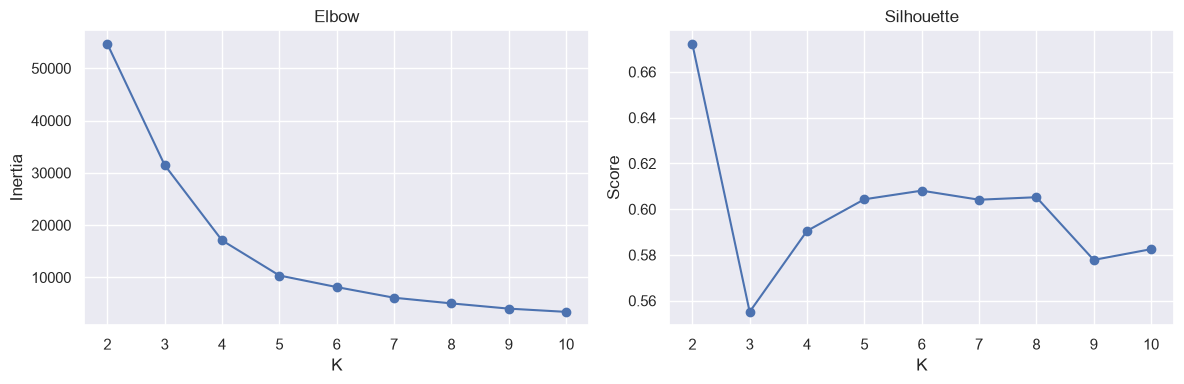

,K,Inertia,Silhouette
0,2,54671.098503,0.672250
1,3,31481.124168,0.555122
2,4,17088.444367,0.590513
3,5,10367.708897,0.604323
4,6,8154.988062,0.608100
5,7,6117.535336,0.604136
6,8,5032.612542,0.605232
7,9,4032.650917,0.577824
8,10,3411.589923,0.582523


In [33]:
# 7. Clustering — K-Means (Kiểm tra ma trận đặc trưng, loại ID/leakage, chuẩn hóa StandardScaler, Elbow & Silhouette)
from sklearn.preprocessing import StandardScaler

if "df" not in globals() or not any(c.startswith("Skill_") for c in df.columns):
    df = pd.read_csv(CLEAN_PATH)
skill_cols = [c for c in df.columns if c.startswith("Skill_")]

# Chỉ chọn kỹ năng (nhị phân) + Experience_Years; loại bỏ hoàn toàn ID, URL, lương, target
leak_or_id = {"Job_ID", "url", "URL_Goc", "Luong_Min", "Luong_Max", "Luong_Min_VND", "Luong_Max_VND", "Luong_Mid_VND", "Seniority_EDA", "Seniority_Target", "Cluster"}
cluster_features = [c for c in skill_cols if c not in leak_or_id]
if "Experience_Years" in df.columns:
    cluster_features.append("Experience_Years")

assert not (set(cluster_features) & leak_or_id), "Phát hiện cột ID/leakage trong feature matrix!"
X_cluster_raw = df[cluster_features].replace([np.inf, -np.inf], np.nan)
X_cluster_raw = X_cluster_raw.loc[:, X_cluster_raw.nunique(dropna=True) > 1]
print(f"Feature matrix: {X_cluster_raw.shape[0]} mẫu × {X_cluster_raw.shape[1]} đặc trưng | Missing trước impute: {int(X_cluster_raw.isna().sum().sum())}")

# Impute median cho Experience_Years (không gán 0) rồi chuẩn hóa StandardScaler
X_cluster_imp = SimpleImputer(strategy="median").fit_transform(X_cluster_raw)
X_cluster_scaled = StandardScaler().fit_transform(X_cluster_imp)

ks = list(range(2, min(10, len(X_cluster_scaled) - 1) + 1))
inertias, sils = [], []
for k in ks:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = model.fit_predict(X_cluster_scaled)
    inertias.append(model.inertia_)
    sils.append(silhouette_score(X_cluster_scaled, labels))

k_metrics = pd.DataFrame({"K": ks, "Inertia": np.round(inertias, 2), "Silhouette": np.round(sils, 4)})
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertias, marker="o"); ax[0].set(title="Elbow Method (StandardScaler)", xlabel="Số cụm K", ylabel="Inertia")
ax[1].plot(ks, sils, marker="o"); ax[1].set(title="Silhouette Score (StandardScaler)", xlabel="Số cụm K", ylabel="Silhouette")
plt.tight_layout(); plt.show()
display(k_metrics)


In [34]:
# 7.1. Chọn K có căn cứ (Elbow + đỉnh Silhouette ở K >= 3) & Diễn giải chân dung cụm
cand = k_metrics[k_metrics["K"] >= 3]
CHOSEN_K = int(cand.loc[cand["Silhouette"].idxmax(), "K"])
chosen_sil = float(cand.loc[cand["Silhouette"].idxmax(), "Silhouette"])
print(f"Chọn K = {CHOSEN_K} (Silhouette = {chosen_sil:.4f}; lưu ý K=2 có Silhouette={k_metrics.loc[k_metrics['K']==2, 'Silhouette'].values[0]:.4f} nhưng chỉ tách 1 nhóm nhỏ khỏi phần còn lại, quá thô để phân khúc).")

km = KMeans(n_clusters=CHOSEN_K, random_state=RANDOM_STATE, n_init=20)
df["Cluster"] = km.fit_predict(X_cluster_scaled)

size_tbl = df["Cluster"].value_counts().sort_index().to_frame("Job_Count")
size_tbl["Percent (%)"] = (size_tbl["Job_Count"] / len(df) * 100).round(2)
display(size_tbl)

sk_in_cluster = [c for c in X_cluster_raw.columns if c.startswith("Skill_")]
profile_skills = df.groupby("Cluster")[sk_in_cluster].mean()
exp_stats = df.groupby("Cluster")["Experience_Years"].agg(["count", "median", "mean"]).round(2)

# Diễn giải tự động từng cụm bằng top 6 kỹ năng đặc trưng & kinh nghiệm
rows_summary = []
for cid in sorted(df["Cluster"].unique()):
    top_sk = profile_skills.loc[cid].sort_values(ascending=False).head(6)
    top_str = ", ".join([f"{k.replace('Skill_', '')} ({v*100:.0f}%)" for k, v in top_sk.items() if v > 0])
    n_c = int(size_tbl.loc[cid, "Job_Count"])
    rows_summary.append({
        "Cluster": cid,
        "Job_Count": n_c,
        "Percent (%)": round(n_c / len(df) * 100, 2),
        "Exp_Valid_n": int(exp_stats.loc[cid, "count"]),
        "Exp_Mean_Years": exp_stats.loc[cid, "mean"],
        "Top_Skills": top_str,
    })
cluster_summary = pd.DataFrame(rows_summary)
display(cluster_summary)

# Heatmap tỷ lệ kỹ năng nổi bật theo cụm
top_var_skills = profile_skills.max(axis=0).sort_values(ascending=False).head(15).index.tolist()
plt.figure(figsize=(12, 4))
hm = profile_skills[top_var_skills].copy()
hm.columns = [c.replace("Skill_", "") for c in hm.columns]
sns.heatmap(hm, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title(f"Tỷ lệ xuất hiện kỹ năng nổi bật theo {CHOSEN_K} cụm (n = {len(df)})")
plt.ylabel("Cluster"); plt.tight_layout(); plt.show()


Cluster
0    245
1    644
Name: count, dtype: int64

,Skill_airflow,Skill_aws,Skill_azure,Skill_c,Skill_computer_vision,Skill_dbt,Skill_deep_learning,Skill_docker,Skill_etl,Skill_excel,Skill_gcp,Skill_hadoop,Skill_java,Skill_javascript,Skill_jenkins,Skill_kafka,Skill_kubernetes,Skill_linux,Skill_looker,Skill_machine_learning,Skill_mongodb,Skill_mysql,Skill_nlp,Skill_numpy,Skill_opencv,Skill_oracle,Skill_pandas,Skill_postgresql,Skill_power_bi,Skill_python,Skill_pytorch,Skill_r,Skill_redis,Skill_scala,Skill_scikit_learn,Skill_spark,Skill_sql,Skill_sql_server,Skill_tableau,Skill_tensorflow,Experience_Years
Cluster,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0.032653,0.191837,0.175510,0.020408,0.016327,0.036735,0.012245,0.138776,0.069388,0.167347,0.077551,0.004082,0.167347,0.069388,0.053061,0.073469,0.114286,0.102041,0.012245,0.069388,0.040816,0.069388,0.024490,0.008163,0.000000,0.122449,0.012245,0.134694,0.118367,0.404082,0.024490,0.363265,0.048980,0.020408,0.012245,0.036735,0.481633,0.089796,0.032653,0.020408,38.040816
1,0.021739,0.063665,0.062112,0.048137,0.029503,0.013975,0.023292,0.116460,0.052795,0.327640,0.034161,0.004658,0.072981,0.054348,0.034161,0.041925,0.068323,0.076087,0.017081,0.063665,0.059006,0.051242,0.021739,0.013975,0.007764,0.118012,0.020186,0.091615,0.169255,0.357143,0.037267,0.406832,0.041925,0.004658,0.020186,0.017081,0.478261,0.072981,0.057453,0.031056,12.359287


In [35]:
# 8. Association Rules — FP-Growth
if skill_cols:
    transactions=df[skill_cols].astype(bool)
    display(transactions.mean().sort_values(ascending=False).head(30).to_frame("Support"))
    MIN_SUPPORT=0.03 
    frequent=fpgrowth(transactions,min_support=MIN_SUPPORT,use_colnames=True)
    if not frequent.empty:
        rules=association_rules(frequent,metric="confidence",min_threshold=0.30)
        if not rules.empty:
            selected_rules=rules[rules["lift"]>1.2].sort_values(["lift","confidence"],ascending=False)
            display(selected_rules[["antecedents","consequents","support","confidence","lift","conviction"]].head(30))
        else: print("Không sinh được luật; xem lại ngưỡng support/confidence.")
    else: print("Không có frequent itemsets ở ngưỡng này; cân nhắc chỉnh min_support.")
else: print("Chưa có cột kỹ năng one-hot.")

,Support
Skill_sql,0.479190
Skill_r,0.394826
Skill_python,0.370079
Skill_excel,0.283465
Skill_power_bi,0.155231
Skill_docker,0.122610
Skill_oracle,0.119235
Skill_postgresql,0.103487
Skill_aws,0.098988
Skill_java,0.098988


,antecedents,consequents,support,confidence,lift,conviction
201,frozenset({Skill_gcp}),"frozenset({Skill_azure, Skill_aws})",0.031496,0.682927,10.118699,2.940988
196,"frozenset({Skill_azure, Skill_aws})",frozenset({Skill_gcp}),0.031496,0.466667,10.118699,1.788526
197,"frozenset({Skill_azure, Skill_gcp})",frozenset({Skill_aws}),0.031496,1.000000,10.102273,inf
200,frozenset({Skill_aws}),"frozenset({Skill_azure, Skill_gcp})",0.031496,0.318182,10.102273,1.420472
192,frozenset({Skill_gcp}),frozenset({Skill_aws}),0.041620,0.902439,9.116685,9.235377
191,frozenset({Skill_aws}),frozenset({Skill_gcp}),0.041620,0.420455,9.116685,1.645912
214,frozenset({Skill_redis}),frozenset({Skill_postgresql}),0.037120,0.846154,8.176421,5.827334
213,frozenset({Skill_postgresql}),frozenset({Skill_redis}),0.037120,0.358696,8.176421,1.490915
198,"frozenset({Skill_aws, Skill_gcp})",frozenset({Skill_azure}),0.031496,0.756757,8.105503,3.727284
199,frozenset({Skill_azure}),"frozenset({Skill_aws, Skill_gcp})",0.031496,0.337349,8.105503,1.446283


In [36]:
# Classification 
def infer_seniority(row):
    title=str(row.get("job_title","")).lower()
    exp=row.get("Experience_Years",np.nan)
    if any(k in title for k in ["intern","thực tập","fresher"]): return "Fresher"
    if any(k in title for k in ["lead","manager"]): return "Lead"
    if "senior" in title: return "Senior"
    if "middle" in title or "mid-level" in title: return "Middle"
    if pd.notna(exp):
        if exp<=1: return "Fresher/Junior"
        if exp<=3: return "Junior"
        if exp<=5: return "Middle"
        return "Senior"
    return np.nan

df["Seniority_Target"]=df.apply(infer_seniority,axis=1)
display(df["Seniority_Target"].value_counts(dropna=False))
TARGET="Seniority_Target"  # đổi nếu nhóm chọn salary band

Seniority_Target
Senior            662
Lead               83
NaN                70
Fresher            35
Middle             17
Fresher/Junior     13
Junior              9
Name: count, dtype: int64

In [37]:
# Chia train/test và tiền xử lý
model_df=df.dropna(subset=[TARGET]).copy()
y=model_df[TARGET].astype(str)
X_cols=skill_cols.copy()
if "Location_Normalized" in model_df.columns: X_cols.append("Location_Normalized")
X=model_df[X_cols].copy()

counts=y.value_counts()
keep=y.isin(counts[counts>=2].index)
X,y=X.loc[keep],y.loc[keep]
display(y.value_counts())

if y.nunique()>=2 and len(y)>=10:
    X_train,X_test,y_train,y_test=train_test_split(
        X,y,test_size=0.2,random_state=RANDOM_STATE,stratify=y)
    numeric=[c for c in X.columns if c.startswith("Skill_")]
    categorical=[c for c in X.columns if c=="Location_Normalized"]
    prep=ColumnTransformer([
        ("num",SimpleImputer(strategy="median"),numeric),
        ("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
                         ("onehot",OneHotEncoder(handle_unknown="ignore"))]),categorical)
    ])
else:
    print("Không đủ dữ liệu/lớp để train-test stratified split.")

Seniority_Target
Senior            662
Lead               83
Fresher            35
Middle             17
Fresher/Junior     13
Junior              9
Name: count, dtype: int64

In [38]:
# Decision Tree — chọn ccp_alpha bằng cross-validation trên train
if "X_train" in globals():
    path_model=Pipeline([("prep",prep),("tree",DecisionTreeClassifier(random_state=RANDOM_STATE,class_weight="balanced"))])
    path_model.fit(X_train,y_train)
    Xtr=path_model.named_steps["prep"].transform(X_train)
    pruning=DecisionTreeClassifier(random_state=RANDOM_STATE).cost_complexity_pruning_path(Xtr,y_train)
    alphas=np.unique(pruning.ccp_alphas)
    if len(alphas)>25: alphas=np.unique(np.quantile(alphas,np.linspace(0,1,25)))
    min_class=int(y_train.value_counts().min())
    if min_class>=2:
        cv=StratifiedKFold(n_splits=min(5,min_class),shuffle=True,random_state=RANDOM_STATE)
        grid=GridSearchCV(path_model,{"tree__ccp_alpha":alphas},scoring="f1_macro",cv=cv,n_jobs=-1)
        grid.fit(X_train,y_train)
        dt_model=grid.best_estimator_
        print("Best params:",grid.best_params_)
    else: print("Một lớp có dưới 2 mẫu trong train; cần gộp/loại lớp hoặc thêm dữ liệu.")

Best params: {'tree__ccp_alpha': np.float64(0.0)}


In [39]:
# Mô hình đối sánh — Random Forest
if "X_train" in globals():
    rf_model=Pipeline([("prep",prep),("rf",RandomForestClassifier(
        n_estimators=300,random_state=RANDOM_STATE,class_weight="balanced",min_samples_leaf=2))])
    rf_model.fit(X_train,y_train)

Decision Tree
                precision    recall  f1-score   support

       Fresher       0.06      0.14      0.08         7
Fresher/Junior       0.20      0.67      0.31         3
        Junior       0.00      0.00      0.00         2
          Lead       0.07      0.12      0.09        17
        Middle       0.10      0.33      0.15         3
        Senior       0.84      0.51      0.63       132

      accuracy                           0.45       164
     macro avg       0.21      0.29      0.21       164
  weighted avg       0.69      0.45      0.53       164

Accuracy: 0.4451 | Precision Macro: 0.2109 | Recall Macro: 0.2947 | Macro F1: 0.2107


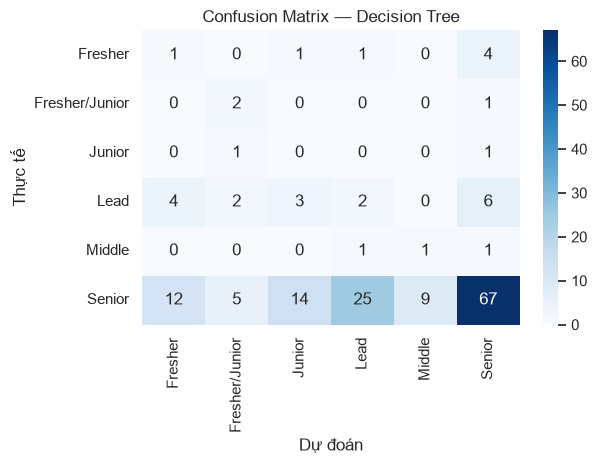

Random Forest
                precision    recall  f1-score   support

       Fresher       0.03      0.14      0.05         7
Fresher/Junior       0.08      0.67      0.15         3
        Junior       0.00      0.00      0.00         2
          Lead       0.09      0.18      0.12        17
        Middle       0.00      0.00      0.00         3
        Senior       0.88      0.37      0.52       132

      accuracy                           0.34       164
     macro avg       0.18      0.23      0.14       164
  weighted avg       0.72      0.34      0.44       164

Accuracy: 0.3354 | Precision Macro: 0.1796 | Recall Macro: 0.2262 | Macro F1: 0.1397


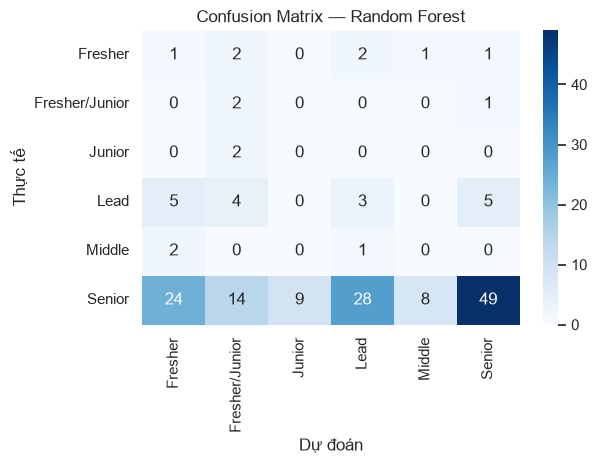

In [40]:
# Confusion Matrix, Precision, Recall, Macro F1
def evaluate(model,name):
    pred=model.predict(X_test)
    print(name)
    print(classification_report(y_test,pred,zero_division=0))
    p,r,f,_=precision_recall_fscore_support(y_test,pred,average="macro",zero_division=0)
    print("Accuracy:",round(accuracy_score(y_test,pred),4),
          "| Precision Macro:",round(p,4),"| Recall Macro:",round(r,4),"| Macro F1:",round(f,4))
    labels=sorted(set(y_test)|set(pred))
    cm=confusion_matrix(y_test,pred,labels=labels)
    sns.heatmap(cm,annot=True,fmt="d",xticklabels=labels,yticklabels=labels,cmap="Blues")
    plt.xlabel("Dự đoán"); plt.ylabel("Thực tế"); plt.title("Confusion Matrix — "+name)
    plt.tight_layout(); plt.show()
    return pred

if "X_test" in globals():
    pred_dt=evaluate(dt_model,"Decision Tree")
    pred_rf=evaluate(rf_model,"Random Forest")

In [41]:
# 10. Xuất kết quả và ghi chú báo cáo
if "skill_counts" in globals():
    skill_counts.to_csv(DATA/"top_skills.csv",header=["Job_Count"],encoding="utf-8-sig")
if "selected_rules" in globals() and not selected_rules.empty:
    selected_rules.to_csv(DATA/"association_rules.csv",index=False,encoding="utf-8-sig")
print("Hoàn tất các bước đã đủ dữ liệu.")

Hoàn tất các bước đã đủ dữ liệu.
